# 第4章：评价的是新记录还是新对象

**学生实验｜全书深化稿**

## 背景与数据
Wine用于基线评价；重复对象模拟给每个对象随机标签，明确构造不可向新对象学习的任务。

## 本次要回答的问题
比较按行与按对象的验证，写清两个分数对应的部署问题。

先写下预判，再运行，最后用实际结果解释；不需要结果符合预期才算成功。

In [1]:
from pathlib import Path
import os, sys
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "experiments/common.py").exists()
             and (p / "main.tex").exists()), None)
if root is None:
    raise RuntimeError("Open this notebook inside the extracted textbook project.")
sys.path.insert(0, str(root / "experiments"))
print("Project:", root)


Project: /mnt/data/book_v3


## 可检查的完整实验代码

下方与对应`experiments`脚本一致。共享的`common.py`只提供固定数据划分、保存表图和绘图设置；模型、目标、参数及比较规则在此明确写出。阅读函数后，再运行下一单元执行实验。

In [2]:
"""Chapter 4: paired folds, baseline and a deliberately grouped leakage demonstration."""
import numpy as np
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_validate,GroupKFold,StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from common import *

def run():
    X,y,_=development('wine'); splits=list(cv5().split(X,y))
    rows=[]
    models={'majority':DummyClassifier(strategy='most_frequent'),
       'scaled logistic':make_pipeline(StandardScaler(),LogisticRegression(C=1,max_iter=3000))}
    for name,m in models.items():
        r=cross_validate(m,X,y,cv=splits,scoring=['accuracy','balanced_accuracy'],return_train_score=True)
        for k in range(5):rows.append({'model':name,'fold':k+1,'train_accuracy':r['train_accuracy'][k],
          'validation_accuracy':r['test_accuracy'][k],'balanced_accuracy':r['test_balanced_accuracy'][k]})
    df=table('ch04_paired_folds',rows);show_result(df)
    # Repeat measurements contain object fingerprints unrelated to an independently generated label.
    rng=np.random.default_rng(40);nobj=90;repeats=5
    centers=rng.normal(size=(nobj,8))*3;labels=rng.integers(0,2,nobj)
    groups=np.repeat(np.arange(nobj),repeats)
    features=centers[groups]+rng.normal(scale=.01,size=(nobj*repeats,8));target=labels[groups]
    configurations={'row split':list(StratifiedKFold(5,shuffle=True,random_state=1).split(features,target)),
       'object split':list(GroupKFold(5).split(features,target,groups))}
    leak=[]
    for name,cv in configurations.items():
        r=cross_validate(KNeighborsClassifier(1),features,target,cv=cv,scoring='accuracy')
        for k,v in enumerate(r['test_score']):leak.append({'split':name,'fold':k+1,'accuracy':float(v)})
    df2=table('ch04_group_demo',leak);show_result(df2)
    plt.figure(figsize=(6.4,4))
    for name in configurations:
        s=df2[df2['split']==name];plt.plot(s.fold,s.accuracy,marker='o',label=name)
    plt.ylim(0,1.05);plt.xlabel('折编号');plt.ylabel('验证准确率');plt.legend();figure('v3_ch04_groups')

In [3]:
result = run()
if result is not None:
    print(result)

          model  fold  train_accuracy  validation_accuracy  balanced_accuracy
       majority     1        0.398230             0.413793           0.333333
       majority     2        0.398230             0.413793           0.333333
       majority     3        0.403509             0.392857           0.333333
       majority     4        0.403509             0.392857           0.333333
       majority     5        0.403509             0.392857           0.333333
scaled logistic     1        1.000000             1.000000           1.000000
scaled logistic     2        1.000000             0.965517           0.972222
scaled logistic     3        1.000000             1.000000           1.000000
scaled logistic     4        1.000000             0.964286           0.969697
scaled logistic     5        1.000000             0.964286           0.969697
       split  fold  accuracy
   row split     1  1.000000
   row split     2  1.000000
   row split     3  1.000000
   row split     4  1.0000

## 检查结果文件与图

下面显示该实验保存的图；所有坐标、样本与数值条件应与正文一致。数据表保存在`results/`。修改代码后，请另存结果或注明变化，不把新配置的输出与正文旧数值混用。

v3_ch04_groups.png


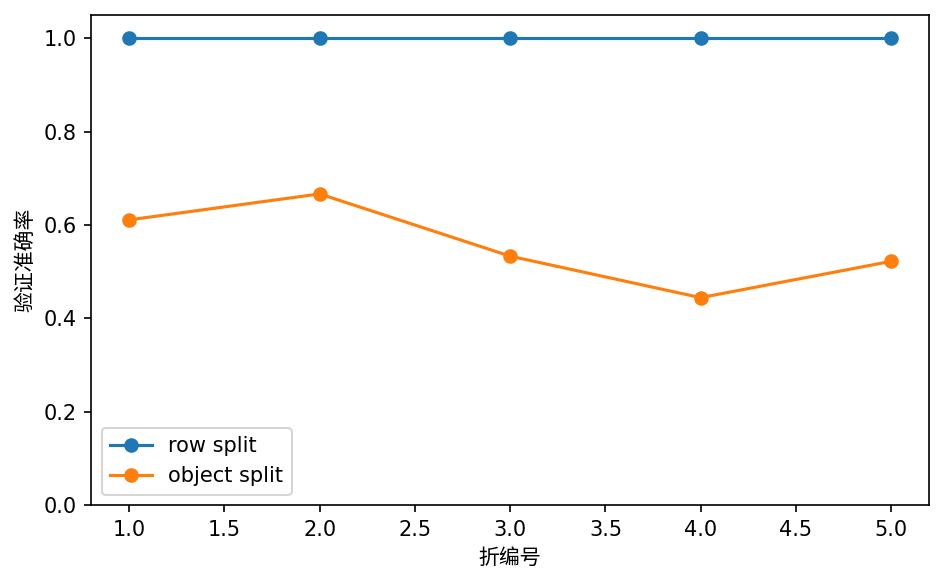

In [4]:
from IPython.display import display, Image
files = sorted((root / "figures").glob("v3_ch04_*.png"))
for path in files:
    print(path.name)
    display(Image(filename=str(path), width=720))
if not files:
    print("This experiment uses tables rather than a new figure.")

## 运行后的分析

解释一个与你的预判一致的结果，再解释一个需要进一步检查的现象。指出训练、验证和测试各使用哪些记录。

比较按行与按对象的验证，写清两个分数对应的部署问题。

**提交要求：**保存可顺序运行的Notebook、一个关键结果表、必要图形，以及150—300字的机制与限制解释。完成正文D题中与本实验相关的计算。不得仅提交最高分截图。